Loading dataset...
Data split complete: 80% for training, 20% for testing.

Training the Random Forest model...
Model Accuracy: 96.49%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.93      0.95        43
      benign       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



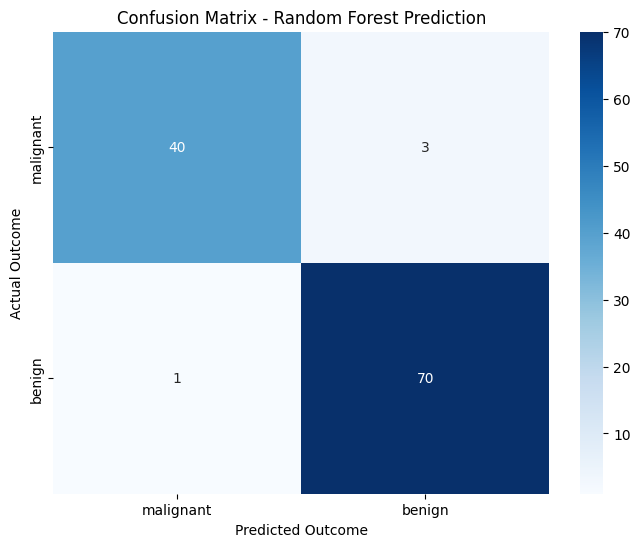

In [1]:
# Import necessary libraries for machine learning and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load the built-in Breast Cancer dataset
print("Loading dataset...")
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names) # Features (inputs)
y = data.target # Target (output to predict)

# 2. Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data split complete: 80% for training, 20% for testing.\n")

# 3. Initialize the Machine Learning model (Random Forest)
model = RandomForestClassifier(random_state=42)

# 4. Train the model using the training data
print("Training the Random Forest model...")
model.fit(X_train, y_train)

# 5. Test the model by making predictions on the unseen test data
y_pred = model.predict(X_test)

# 6. Evaluate and print the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# Print a detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# 7. Visualize the model's performance using a Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title('Confusion Matrix - Random Forest Prediction')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.show()